In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/TransformersCode/customer_serves/photos/fer2013.csv')
display(df.head())

,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


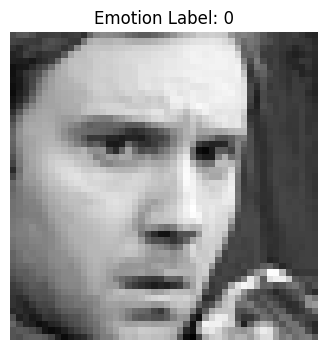

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

first_row = df.iloc[0]
emotion_label = first_row['emotion']
pixel_array = np.array(first_row['pixels'].split(), dtype=np.uint8)
img_array = pixel_array.reshape(48, 48)

plt.figure(figsize=(4, 4))
plt.imshow(img_array, cmap='gray')
plt.title(f"Emotion Label: {emotion_label}")
plt.axis('off')
plt.show()

In [62]:
df["pixel_array"] = df["pixels"].apply(
    lambda x: np.array(x.split(), dtype=np.uint8).reshape(48, 48)
)

# عرض أول صفين للتأكد من نجاح العملية
print(df[["emotion", "pixel_array"]].head())

   emotion                                        pixel_array
0        0  [[70, 80, 82, 72, 58, 58, 60, 63, 54, 58, 60, ...
1        0  [[151, 150, 147, 155, 148, 133, 111, 140, 170,...
2        2  [[231, 212, 156, 164, 174, 138, 161, 173, 182,...
3        4  [[24, 32, 36, 30, 32, 23, 19, 20, 30, 41, 21, ...
4        6  [[4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 15, 2...


In [63]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
import torch

# 1. مسار الصورة في جوجل كولاب
image_path = "/content/drive/MyDrive/TransformersCode/customer_serves/photos/fish.JPEG"

# 2. تحميل الصورة باستخدام PIL والتأكد من أنها ملونة (RGB)
image = Image.open(image_path).convert("RGB")

# 3. اسم النموذج الذي اخترته
model_name = "google/vit-base-patch16-224"

# 4. تحميل المعالج (Processor) والنموذج
print("جاري تحميل النموذج والمعالج...")
processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModelForImageClassification.from_pretrained(model_name)

# 5. تجهيز الصورة لتتطابق مع متطلبات النموذج (تغيير الحجم والـ Normalization)
inputs = processor(images=image, return_tensors="pt")

# 6. تمرير الصورة عبر النموذج للحصول على التوقعات (Inference)
with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits

# 7. استخراج الفئة ذات الاحتمالية الأعلى
predicted_class_idx = logits.argmax(-1).item()
predicted_class_name = model.config.id2label[predicted_class_idx]

print(f"\n✨ النتيجة المتوقعة للنموذج: {predicted_class_name}")

جاري تحميل النموذج والمعالج...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]


✨ النتيجة المتوقعة للنموذج: goldfish, Carassius auratus


In [64]:
df["emotion"].value_counts()

,count
emotion,
3,8989
6,6198
4,6077
2,5121
0,4953
5,4002
1,547


In [65]:
min_count = df['emotion'].value_counts().min()
balanced_df = df.groupby('emotion', group_keys=False).apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)
print(balanced_df['emotion'].value_counts())

emotion
0    547
1    547
2    547
3    547
4    547
5    547
6    547
Name: count, dtype: int64


/tmp/ipykernel_2289/2430069688.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced_df = df.groupby('emotion', group_keys=False).apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)


In [66]:
import numpy as np
from transformers import Trainer, TrainingArguments


def evaluate_model(model, eval_dataset, processor):
  """دالة لتقييم نموذج Vision Transformer وعرض إجمالي البيانات، التوقعات الصحيحة، والنسبة المئوية"""

  # 1. إعدادات التقييم المؤقتة
  eval_args = TrainingArguments(
      output_dir="./eval_output",
      per_device_eval_batch_size=16,
      report_to="none",  # لمنع أي تسجيل خارجي
  )

  # 2. إنشاء Trainer خاص بالتقييم
  eval_trainer = Trainer(
      model=model, args=eval_args, eval_dataset=eval_dataset, tokenizer=processor
  )

  print("🔍 جاري تقييم النموذج...")
  predictions_output = eval_trainer.predict(eval_dataset)

  # 3. استخراج التوقعات (Preds) والتصنيفات الحقيقية (Labels)
  preds = np.argmax(predictions_output.predictions, axis=1)
  labels = predictions_output.label_ids

  # 4. حساب الإحصائيات
  total_samples = len(labels)
  correct_predictions = np.sum(preds == labels)
  accuracy = (correct_predictions / total_samples) * 100

  # 5. طباعة التقرير النهائي بشكل مرتب
  print("\n" + "=" * 45)
  print("📊 تقرير تقييم النموذج:")
  print("=" * 45)
  print(f"🔹 إجمالي عدد البيانات (صور التقييم): {total_samples}")
  print(f"🔹 عدد التوقعات الصحيحة: {correct_predictions}")
  print(f"🔹 النسبة المئوية للدقة: {accuracy:.2f}%")
  print("=" * 45)

  return accuracy, preds, labels



In [67]:
import numpy as np
from transformers import Trainer, TrainingArguments

def evaluate_model(model, eval_dataset, processor):
    eval_args = TrainingArguments(
        output_dir="./eval_output",
        per_device_eval_batch_size=16,
        report_to="none",
        remove_unused_columns=False
    )

    eval_trainer = Trainer(
        model=model,
        args=eval_args,
        eval_dataset=eval_dataset,
        processing_class=processor
    )

    predictions_output = eval_trainer.predict(eval_dataset)
    preds = np.argmax(predictions_output.predictions, axis=1)
    labels = predictions_output.label_ids

    total_samples = len(labels)
    correct_predictions = np.sum(preds == labels)
    accuracy = (correct_predictions / total_samples) * 100

    print(f"Total samples: {total_samples}")
    print(f"Correct predictions: {correct_predictions}")
    print(f"Accuracy: {accuracy:.2f}%")

    return accuracy, preds, labels

In [68]:
# إعادة استدعاء دالة التقييم بعد تعطيل خاصية إزالة الأعمدة التلقائية
accuracy, predictions, true_labels = evaluate_model(
    model, encoded_eval, processor
)

Total samples: 574
Correct predictions: 0
Accuracy: 0.00%


In [69]:
from datasets import Dataset
from PIL import Image
import numpy as np
import os
from transformers import AutoImageProcessor, AutoModelForImageClassification

model_name = "google/vit-base-patch16-224"
processor = AutoImageProcessor.from_pretrained(model_name)

model = AutoModelForImageClassification.from_pretrained(
    model_name,
    num_labels=7,
    ignore_mismatched_sizes=True
)

hf_dataset = Dataset.from_pandas(balanced_df.drop(columns=["pixel_array"], errors="ignore"))

train_test_split = hf_dataset.train_test_split(test_size=0.3, seed=42)
test_eval_split = train_test_split["test"].train_test_split(test_size=0.5, seed=42)

train_df = train_test_split["train"].to_pandas()
eval_df = test_eval_split["train"].to_pandas()
test_df = test_eval_split["test"].to_pandas()

save_path = "/content/drive/MyDrive/TransformersCode/customer_serves/photos"
os.makedirs(save_path, exist_ok=True)

train_df.to_csv(f"{save_path}/train_split.csv", index=False)
eval_df.to_csv(f"{save_path}/eval_split.csv", index=False)
test_df.to_csv(f"{save_path}/test_split.csv", index=False)

final_splits = {
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(eval_df),
    "test": Dataset.from_pandas(test_df)
}

def transform_images(examples):
    images = []
    for pixel_str in examples["pixels"]:
        pixel_array = np.array(pixel_str.split(), dtype=np.uint8).reshape(48, 48)
        img = Image.fromarray(pixel_array).convert("RGB")
        images.append(img)
    inputs = processor(images, return_tensors="pt")
    inputs["labels"] = examples["emotion"]
    return inputs

encoded_train = final_splits["train"].with_transform(transform_images)
encoded_eval = final_splits["validation"].with_transform(transform_images)
encoded_test = final_splits["test"].with_transform(transform_images)

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [70]:
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="./vit_emotion_results",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    save_strategy="epoch",
    logging_steps=20,
    load_best_model_at_end=True,
    remove_unused_columns=False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_train,
    eval_dataset=encoded_eval,
    processing_class=processor
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,1.354868,1.267744
2,0.912423,1.163555
3,0.774925,1.138868


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=504, training_loss=1.1416169414444575, metrics={'train_runtime': 425.357, 'train_samples_per_second': 18.902, 'train_steps_per_second': 1.185, 'total_flos': 6.230635168562381e+17, 'train_loss': 1.1416169414444575, 'epoch': 3.0})

In [71]:
predictions_output = trainer.predict(encoded_test)
preds = np.argmax(predictions_output.predictions, axis=1)
labels = predictions_output.label_ids

total_samples = len(labels)
correct_predictions = np.sum(preds == labels)
accuracy = (correct_predictions / total_samples) * 100

print(f"Total samples: {total_samples}")
print(f"Correct predictions: {correct_predictions}")
print(f"Accuracy: {accuracy:.2f}%")

Total samples: 575
Correct predictions: 331
Accuracy: 57.57%


In [72]:
import os
import shutil

save_directory = "/content/drive/MyDrive/TransformersCode/customer_serves/vit_emotion_model"

if os.path.exists(save_directory):
    shutil.rmtree(save_directory)

os.makedirs(save_directory, exist_ok=True)

trainer.save_model(save_directory)
processor.save_pretrained(save_directory)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['/content/drive/MyDrive/TransformersCode/customer_serves/vit_emotion_model/preprocessor_config.json']